# Phase 2: Exploratory data analysis

Dataset built by `scripts/build_dataset.py` (see `docs/datasheet.md`). This notebook re-runs the
analysis functions in `scripts/eda.py`, shows the saved figures and records the manual label audit.
Every number printed below is computed live from `data/processed/*.csv`.

In [1]:
import sys, json, os
sys.path.insert(0, os.path.abspath('../src')); sys.path.insert(0, os.path.abspath('../scripts'))
os.chdir('..')
import pandas as pd
from IPython.display import Image, display
from stance.utils import read_data
import eda
train, dev, gold = read_data('data/processed/train.csv'), read_data('data/processed/dev.csv'), read_data('data/gold/test_handcrafted.csv')
stats = json.load(open('results/eda_stats.json', encoding='utf-8'))
print({k: stats[k] for k in ['rows', 'train_len_median', 'gold_len_median', 'train_codemix_mean', 'gold_codemix_mean']})

{'rows': {'train': 19278, 'dev': 1402, 'gold': 306}, 'train_len_median': 107.0, 'gold_len_median': 62.0, 'train_codemix_mean': 0.21281015576071258, 'gold_codemix_mean': 0.1718790935558525}


## Label distribution: overall, per language, per source_type

label,Against,Favour,None,All
language,,,,
bn,1095,5397,2998,9490
hi,1130,5585,3073,9788
All,2225,10982,6071,19278


label,Against,Favour,None,All
source_type,,,,
codemixed,158,1027,535,1720
original,0,471,827,1298
synthetic,610,619,494,1723
translated,1164,7001,3207,11372
transliterated,293,1864,1008,3165
All,2225,10982,6071,19278


label,Against,Favour,None
source,,,
climatestance,751,6537,862
dhoroni,0,1293,2158
gwsd,819,1867,2216
template,610,619,494
tweet_eval_climate,45,666,341


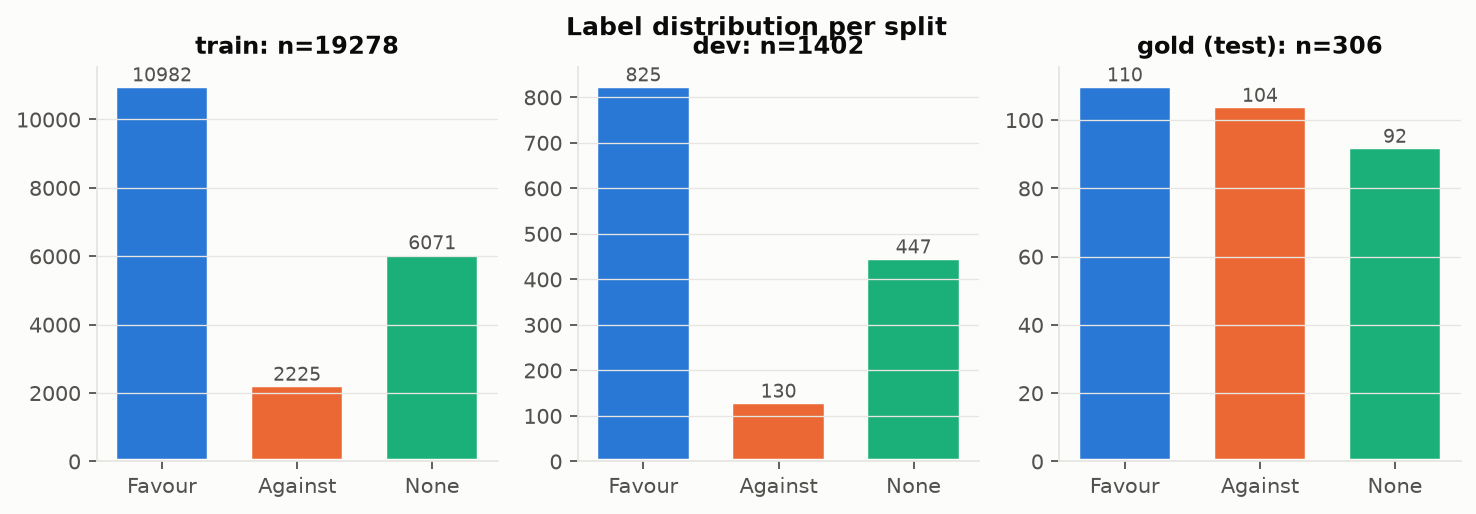

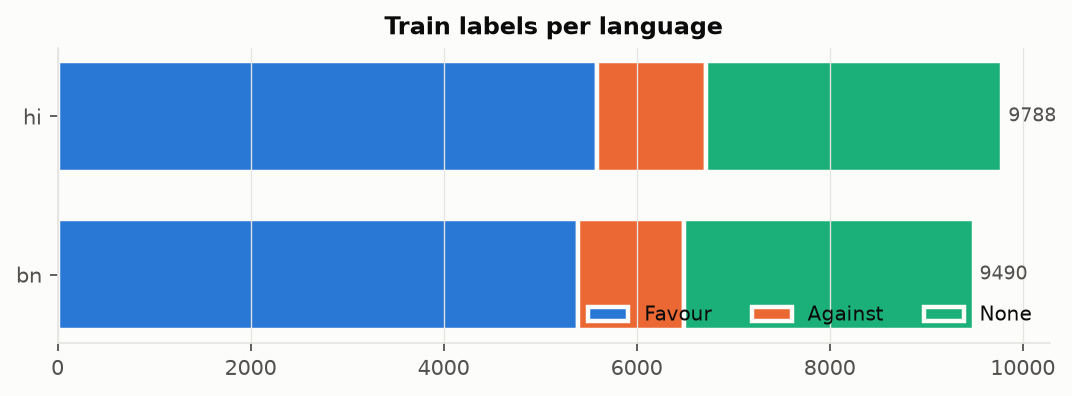

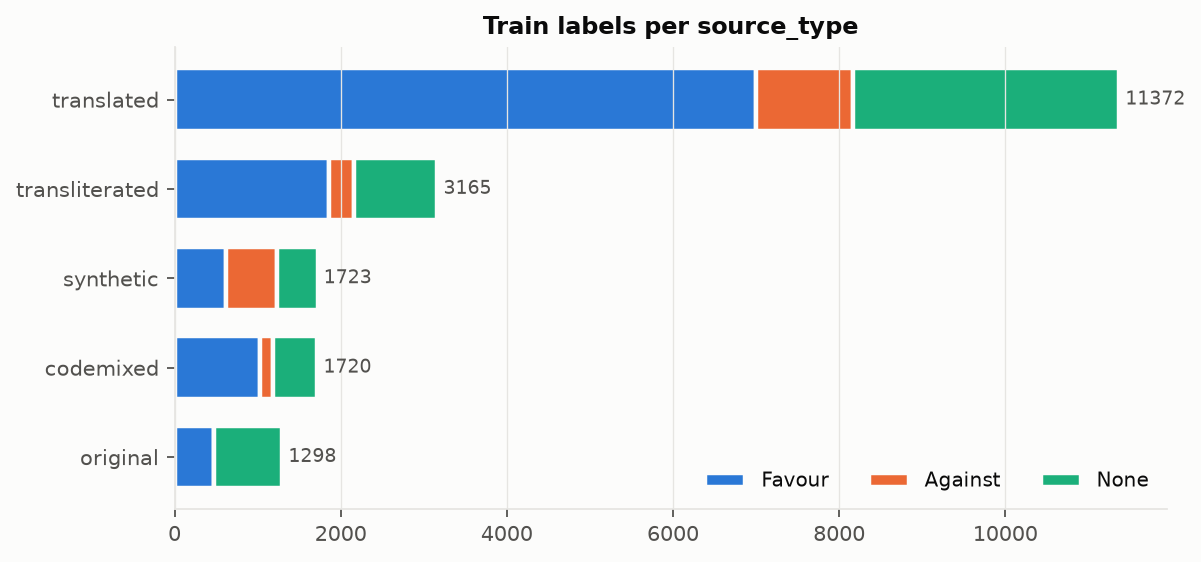

In [2]:
display(pd.crosstab(train.language, train.label, margins=True))
display(pd.crosstab(train.source_type, train.label, margins=True))
display(pd.crosstab(train.source, train.label))
for f in ['label_distribution.png', 'label_by_language.png', 'label_by_source_type.png']: display(Image(f'results/figures/{f}'))

## Script distribution (Devanagari / Bengali / Latin / mixed)

source_type,codemixed,original,synthetic,translated,transliterated
script,,,,,
bengali,350,1298,559,4881,0
devanagari,427,0,568,6284,0
latin,27,0,248,9,3165
mixed,916,0,348,198,0


gold: {'devanagari': 119, 'bengali': 119, 'latin': 44, 'mixed': 22, 'other': 2}


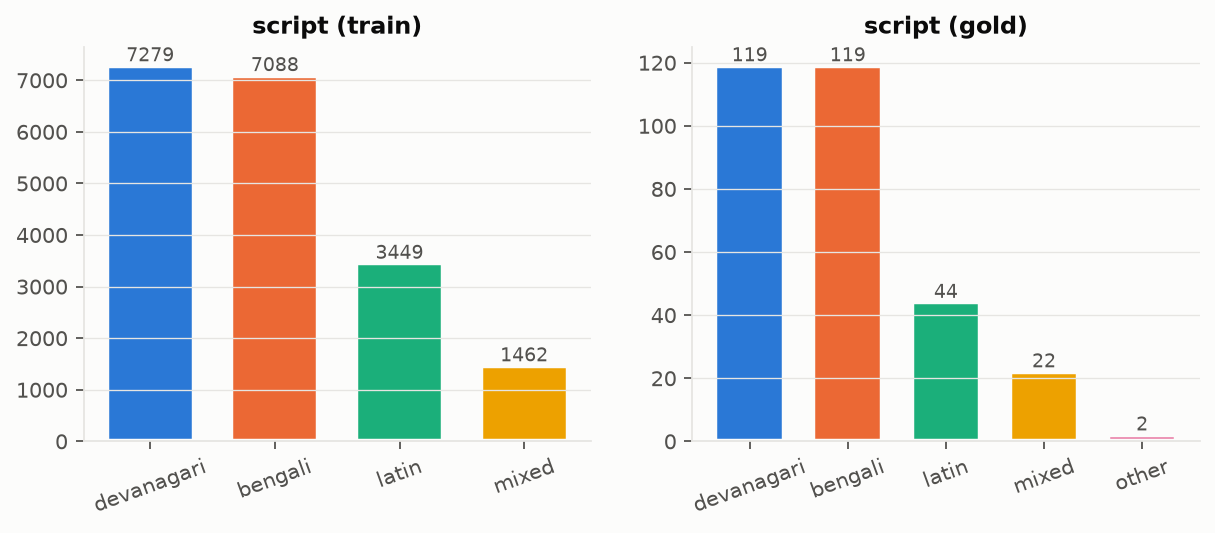

In [3]:
display(pd.crosstab(train.script, train.source_type)); print('gold:', gold.script.value_counts().to_dict())
display(Image('results/figures/script_distribution.png'))

## Text length and code-mixing ratio

count    19278.0
mean       127.6
std         75.7
min          7.0
25%         68.0
50%        107.0
75%        176.0
max        647.0
Name: text, dtype: float64
count    306.0
mean      64.5
std       47.0
min        3.0
25%       46.0
50%       62.0
75%       72.8
max      370.0
Name: text, dtype: float64
mean code-mix ratio per source_type:


source_type
codemixed         0.237
original          0.000
synthetic         0.206
translated        0.015
transliterated    1.000
Name: cm, dtype: float64


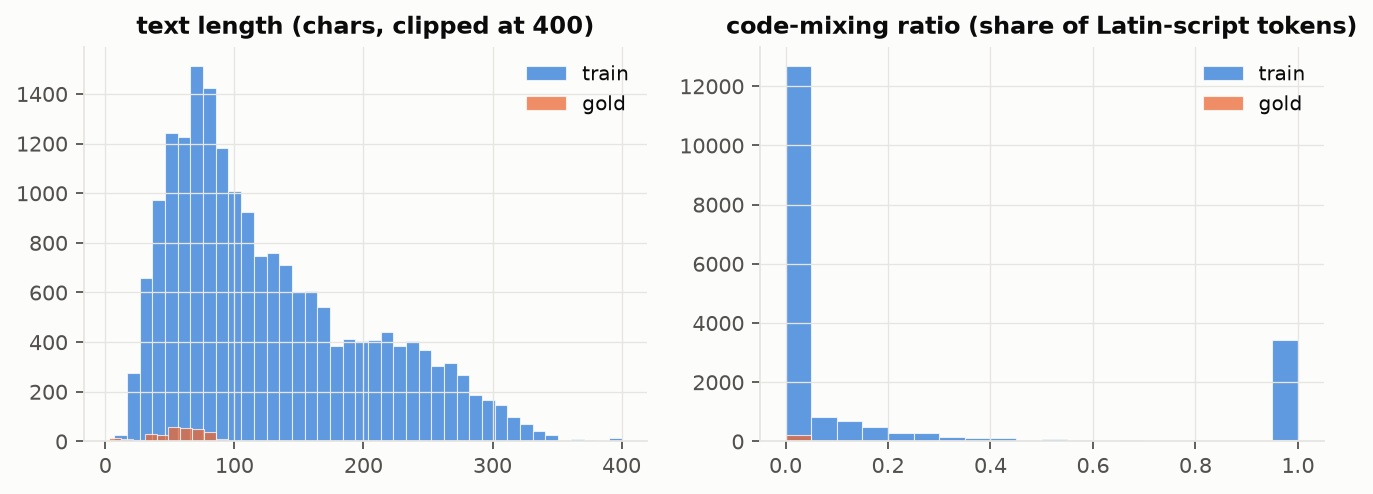

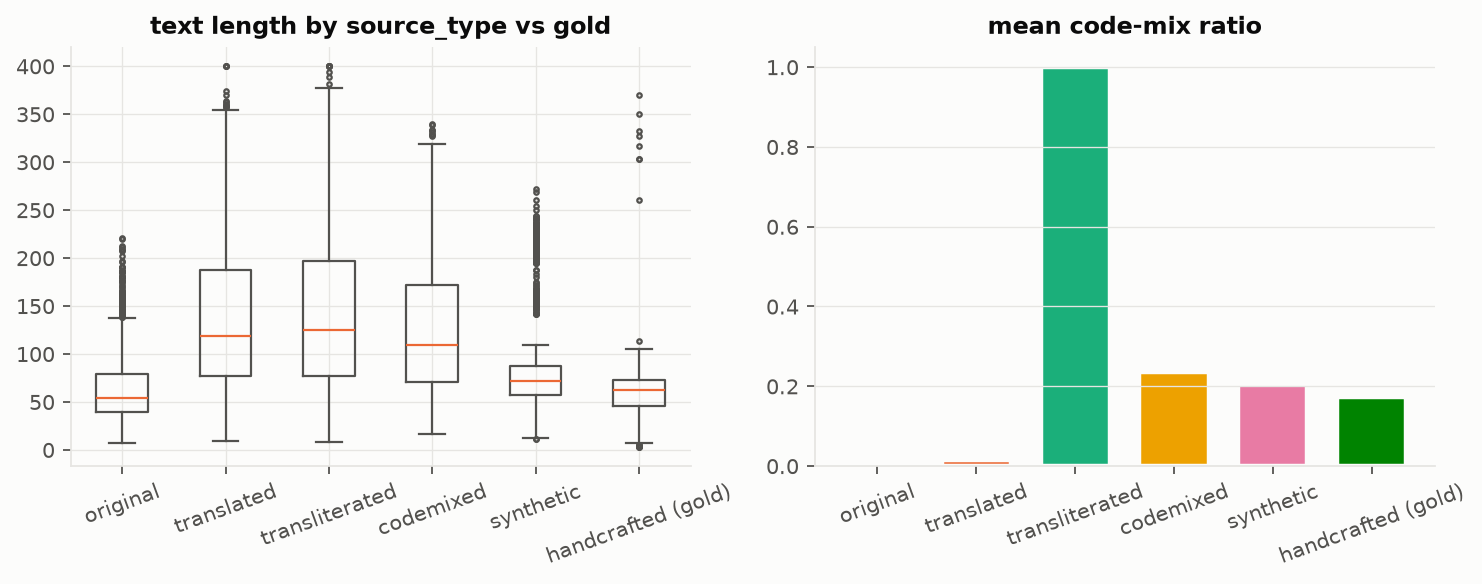

In [4]:
from stance.preprocessing.normalize import code_mix_ratio
print(train.text.str.len().describe().round(1)); print(gold.text.str.len().describe().round(1))
print('mean code-mix ratio per source_type:'); print(train.assign(cm=train.text.map(code_mix_ratio)).groupby('source_type').cm.mean().round(3))
display(Image('results/figures/length_and_codemix.png')); display(Image('results/figures/source_type_vs_gold.png'))

## Top n-grams per class and language

hi/Favour ['जलव', 'वर', 'तन', 'वर तन', 'जलव वर', 'रह', 'करन', 'कर', 'ke', 'नह']
hi/Against ['नह', 'जलव', 'वर', 'तन', 'वर तन', 'जलव वर', 'रह', 'बल', 'इस', 'hai']
hi/None ['वर', 'जलव', 'रह', 'ke', 'तन', 'वर तन', 'जलव वर', 'नह', 'mein', 'करन']
bn/Favour ['পর', 'জলব', 'কর', 'বর', 'পর বর', 'তন', 'বর তন', 'জলব পর', 'এব', 'জন']
bn/Against ['পর', 'কর', 'বর', 'জলব', 'পর বর', 'তন', 'বর তন', 'জলব পর', 'আম', 'ওয']
bn/None ['পর', 'কর', 'বর', 'জলব', 'পর বর', 'তন', 'বর তন', 'এব', 'জলব পর', 'জন']


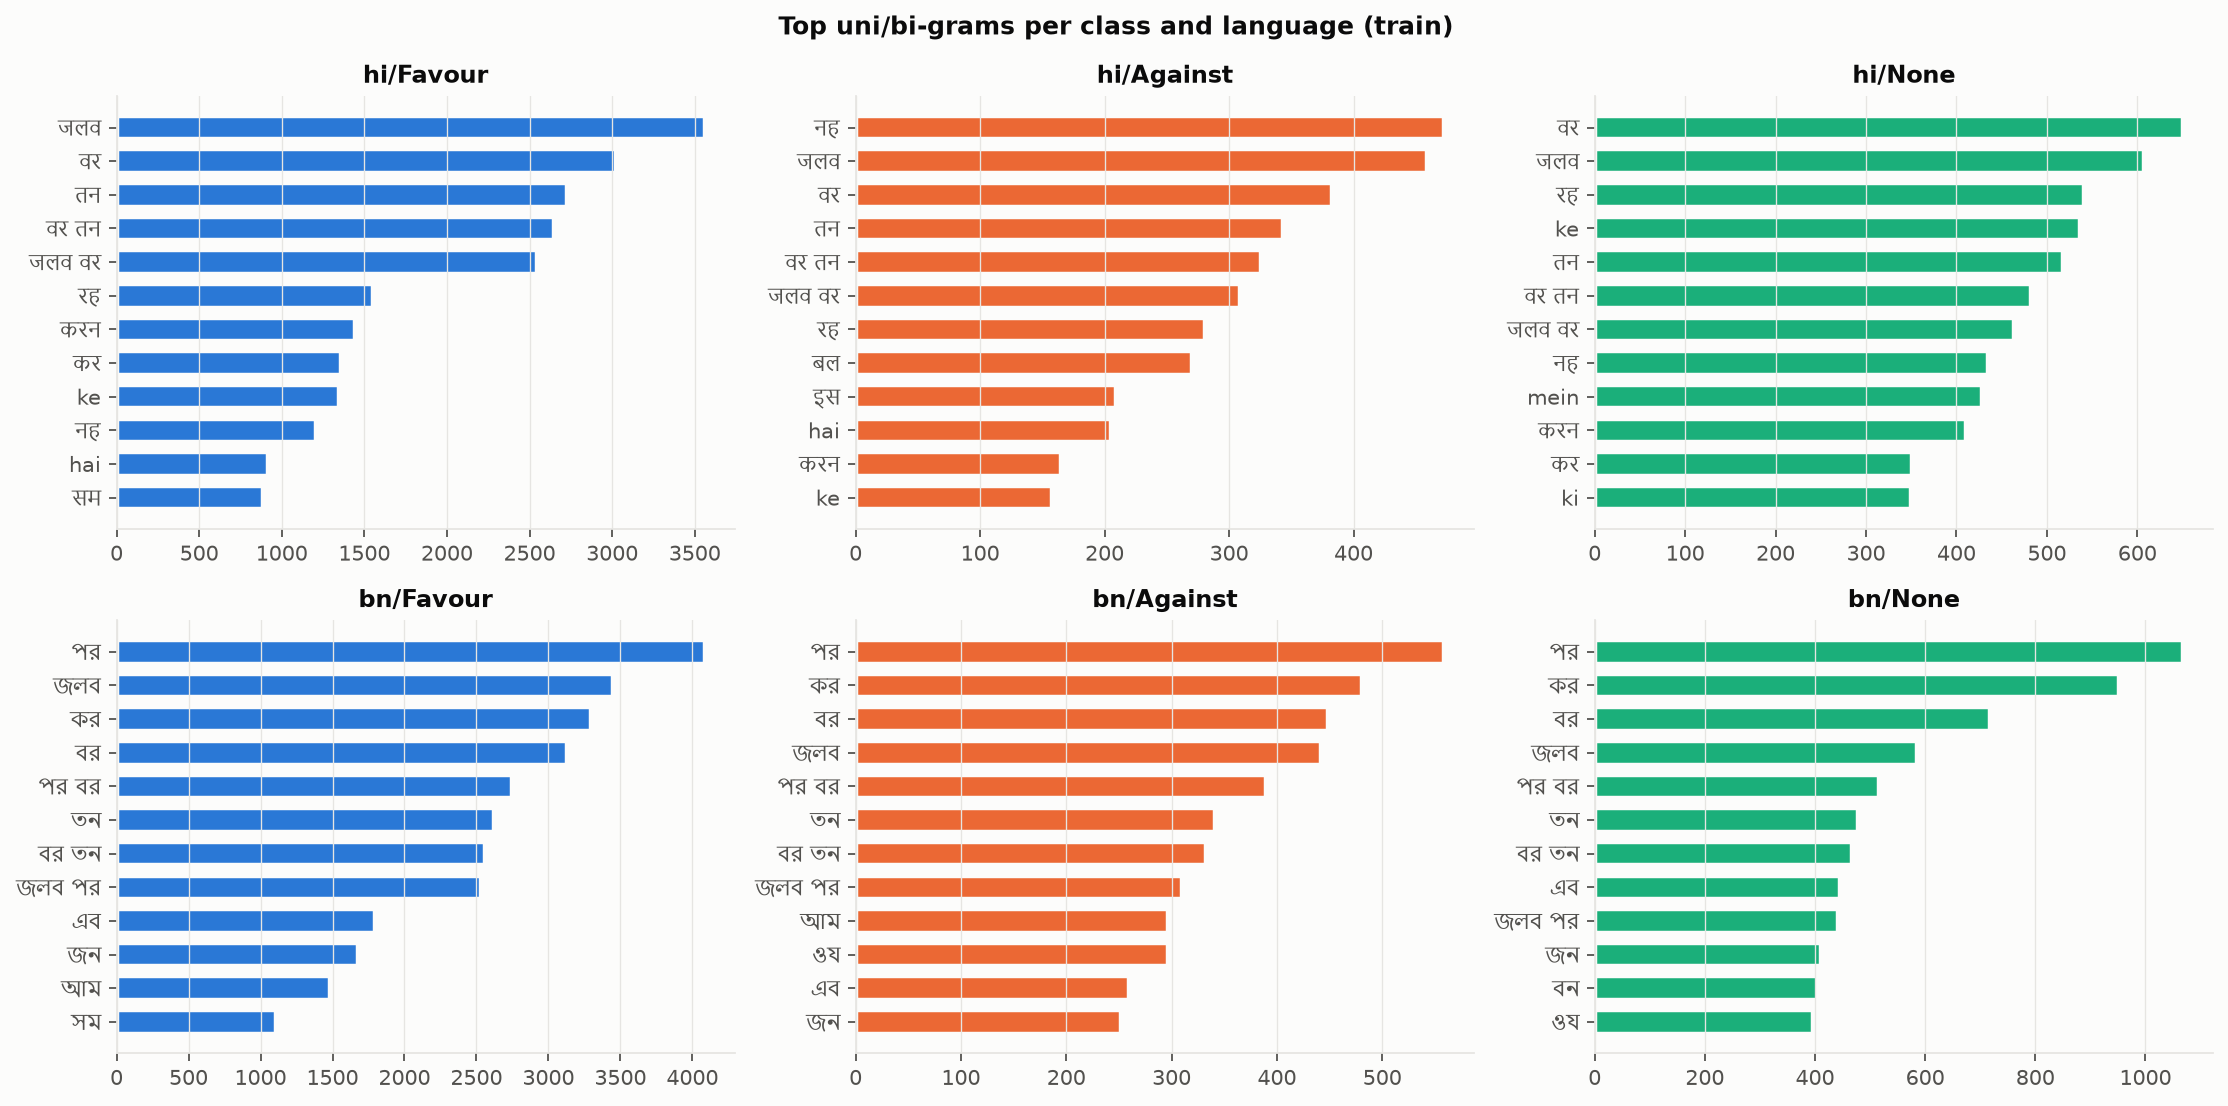

In [5]:
for k, v in stats['top_ngrams'].items(): print(k, [w for w, _ in v[:10]])
display(Image('results/figures/top_ngrams.png'))

## Emoji, URL, hashtag, mention frequency; Romanized share

,train,gold
emoji_share,0.032,0.092
url_share,0.000,0.000
hashtag_share,0.000,0.000
mention_share,0.000,0.000
romanized_indic_share,0.055,0.046
mean_len,127.633,64.539


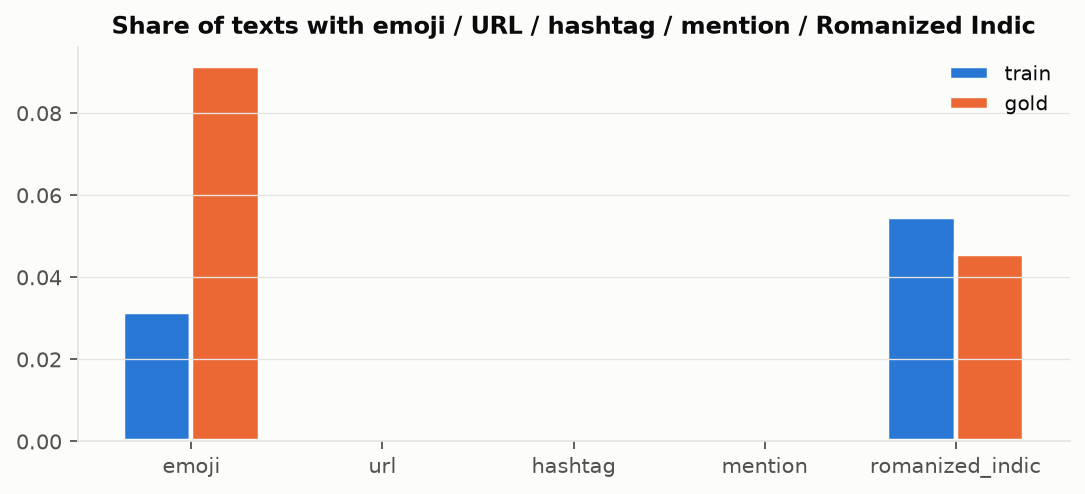

In [6]:
display(pd.DataFrame({'train': stats['surface_train'], 'gold': stats['surface_gold']}).round(3)); display(Image('results/figures/surface_features.png'))

## Duplicates and leakage across splits

In [7]:
print(json.dumps(stats['leakage'], indent=1)); print(json.load(open('data/processed/build_stats.json', encoding='utf-8'))['dedup'])

{
 "train_vs_dev": {
  "exact": 0,
  "near_or_exact": 0,
  "n_other": 1402
 },
 "train_vs_gold": {
  "exact": 0,
  "near_or_exact": 0,
  "n_other": 306
 },
 "train_vs_challenge_mft": {
  "exact": 0,
  "near_or_exact": 0,
  "n_other": 780
 }
}
{'input_rows': 15002, 'dropped_too_short': 0, 'dropped_exact': 596, 'dropped_near': 26, 'output_rows': 14380, 'near_threshold': 0.85, 'example_near_pairs': [[1064, 763], [1216, 1035], [1748, 763], [3591, 3438], [4184, 4157], [4796, 4382], [5031, 3420], [5285, 4168], [5399, 3593], [5471, 4711]]}


## Hard / ambiguous examples (lexicon disagrees with the label on translated rows)

In [8]:
pd.set_option('display.max_colwidth', 160); display(read_data('results/eda_hard_examples.csv').head(20))

,id,text,language,label,lexicon_pred
0,train_007834,वैश्विक कार्बन डाइऑक्साइड उत्सर्जन पिछले दशक की तेजी से गति से कुछ हद तक धीमा हो रहा है।,hi,None,Favour
1,train_004300,২০১৯ সালের লিঙ্কডইন টপ ভয়েসেস তালিকায় গ্লোবাল ইনফ্লুয়েন্সারদের একজন। আমরা সম্মানিত যে আমাদের নির্বাহী চেয়ারম্যানকে তার কার্যকলাপের জন্য স্বীকৃতি দেওয়া ...,bn,Favour,None
2,train_006939,जलवायु परिवर्तन के कारण हमारे सबसे महत्वपूर्ण पर्वत खतरे में हैं,hi,Favour,None
3,train_018742,হ্যালো! আপনি কি এই পডকাস্ট দেখেছেন যেখানে মার্ক ওয়াটসনের মতো যুক্তরাজ্যের শীর্ষস্থানীয় কৌতুকবিদরা কৌতুকের মাধ্যমে জলবায়ু পরিবর্তনকে আকর্ষণীয় করার চেষ্টা...,bn,Favour,Against
4,train_017904,"फैशन उद्योग को अपशिष्ट और प्रदूषण के लिए बढ़ती आलोचना का सामना करना पड़ रहा है, एच एंड एम कपड़े किराए पर लेने की सेवा का परीक्षण कर रहा है। ब्रांड Hn M blme...",hi,Favour,None
5,train_013814,SOAC2019 (पर्थ) से घर (सिडनी) के लिए उड़ान भरना - आग की गंध विमान में प्रवेश करती है जब हम धुएं के आवरण के माध्यम से उड़ते हैं। मुझे आश्चर्य है कि ऑस्ट्रेलि...,hi,Favour,None
6,train_007526,ठीक है जलवायु परिवर्तन महत्वपूर्ण है और सभी लेकिन हमें उन सभी प्रयासों और धन को पुनर्निर्देशित करना चाहिए इसके बजाय इस तरह की चीजों को तुरंत रोकने पर ध्यान ...,hi,Favour,None
7,train_010360,जलवायु परिवर्तन के नाम पर कॉपली स्क्वायर से स्टेट हाउस तक सैकड़ों लोग मार्च कर रहे हैं।,hi,Favour,None
8,train_018636,"গ্লোবাল ওয়ার্মিংয়ের কারণে পৃথিবী জ্বলছে, আমি অনুমান করি?",bn,Favour,None
9,train_008894,"मैक्रो समस्याएं हम सभी का सामना करती हैं, लेकिन लोग सूक्ष्म समस्याओं पर ध्यान केंद्रित करते हैं क्योंकि वे सेम एसटी को ठीक करने के लिए हमारी तत्काल शक्ति के...",hi,Favour,None


## Manual label-noise audit (50 random train rows, seed 42)

Inspected by the author (file `results/eda_label_audit_sample.csv`). Findings on the first build:

* **~8 / 50 rows (about 15 %) have questionable labels**, almost all inherited from the English source labels
  rather than created by translation: spam/advert tweets labelled *Favour* in ClimateStance, a sarcastic
  tweet ("I died in the great ozone cut of 1974") labelled *Favour*, a "brainwashing / mass hysteria" tweet
  labelled *None* (it is *Against*), a Dhoroni tourism headline labelled *Favour*.
* Translation quality itself was mostly adequate for stance (meaning preserved), but long tweets with
  hashtags/usernames produce clumsy sentences ("re के डी शांति सेम एसटी" = leftover handle fragments).
* Two generator bugs surfaced and were fixed before the final build: candra-vowel characters leaking into
  Romanized text ("rikaॉrd"), and code-mix substitution inside words ("peopleों").
* Synthetic template rows are grammatical but repetitive; a few slot fills are awkward
  ("ग्लेशियर पिघलना आती थी").

Implication: label noise of roughly 10-15 % bounds the achievable CV macro F1 on `translated` rows and
makes the **hand-written gold set and the challenge suite the decisive evaluations**, not CV.

In [9]:
display(read_data('results/eda_label_audit_sample.csv'))

,id,text,language,source_type,label
0,train_018667,"संयुक्त राष्ट्र जलवायु परिवर्तन सम्मेलन COP25 से पहले, इंटर IKEA समूह ने घोषणा की है कि वे जलवायु सकारात्मक व्यवसाय बनने के लिए परिवर्तन को तेज करने के लिए ...",hi,translated,Favour
1,train_015574,आलू का मौसम आ रहा है।,hi,translated,None
2,train_000351,क्या हम अब थोरियम एलएफटीआर का निर्माण कर सकते हैं गर्मियों में 200 डिग्री सेल्सियस से पहले।,hi,translated,Favour
3,train_002408,"भाई मौसम में बदलाव कोई मज़ाक नहीं है, लखनऊ में मार्च में ही 42 डिग्री हो रहा है",hi,synthetic,Favour
4,train_009020,"বিদ্যুৎ কেন্দ্র থেকে কার্বন দূষণ কমানোর জন্য ওবামা প্রশাসনের নতুন পরিকল্পনা কেবল জলবায়ু পরিবর্তন মোকাবেলা করবে না, বরং দ্রুত জনস্বাস্থ্যের উন্নতি করবে, এই ...",bn,translated,Favour
5,train_000257,"pahle bhi sukha aati thi, tab koi sajish nahin phailaataa tha",hi,synthetic,Against
6,train_012574,"WRONG, jolbayu poriborton niye alochonay bishal probhab felechhe ebon etike ekti notun torun shrotar kachhe pounchhe diyechhe ya tader pur jibnke sorasri pr...",bn,transliterated,Favour
7,train_009124,"कृषि पर जलवायु परिवर्तन के प्रभावों का सामना करने के लिए खाद्य प्रणालियों को लचीला होने की आवश्यकता होगी। 20 कारकों को देखते हुए, शोधकर्ताओं को अब इस बारे म...",hi,translated,Favour
8,train_004342,Peole@ jalvayu parivartan par bharosaa nahin kiyaa jaa sakta,hi,transliterated,None
9,train_000346,जलवायु परिवर्तन के बारे में लोगों को सोचने के लिए 'अल्पकालिक प्रोत्साहन विकसित करने' की आवश्यकता पर हावर्ड कुनरेथर,hi,translated,Favour


## Insights that change our modelling decisions

1. **Distribution shift is the main risk, not data size.** Train text (median ~107 chars, 58 % machine-translated
   from English tweets/news) is longer, more formal and more "Western" than the gold set (median ~62 chars, written
   as Indian/Bangladeshi comments). -> Select and tune models on gold + challenge results, use dev only for early stopping.
2. **Against is rare in train (11.5 %) but ~1/3 of the hidden test is plausibly Against.** -> class-weighted loss /
   focal loss, per-class threshold tuning on held-out data, and the Against-heavy conspiracy/sarcasm challenge categories.
3. **Scripts**: 18 % of train is Latin-script and 8 % mixed-script (all synthetic Romanization / code-mixing).
   Real Romanized text has more spelling variation than our rules produce -> character n-grams for sparse models,
   MuRIL (pre-trained on transliterated text) first, typo/matra-drop augmentations in Phase 6.
4. **Lexicon agrees with only 40 % of train labels** but reaches a much higher score on gold: translated news-style
   text carries stance implicitly; comments carry it in explicit cue words. A model must do both -> keep the
   target-aware pair input (explicit claim context) and ensemble a cue-sensitive sparse model with the transformer.
5. **No leakage**: 0 exact / near duplicates between train and dev, gold or challenge after group-wise splitting.
6. **Label noise ~15 % in translated rows** (audit above) -> report CV with error bars, do not chase CV decimals,
   and prefer augmentations that help the challenge suite.